# Hypothesis testing by simulation and by formula

A statistical test asks one question: *if nothing interesting were going on, how surprising
would data like mine be?* Textbook formulas answer it analytically; a computer can answer it by
brute force. This notebook does both for every test it introduces, so the formula never becomes
a black box.

**The experiment.** Participants searched for a target among 8, 12, or 16 items and reported
whether it was present. In the *static* condition the display stayed put; in the *dynamic*
condition the items were relocated every 110 ms, so participants could not remember where they
had already looked. The data are openly available at
[msenselab/dynamic_search](https://github.com/msenselab/dynamic_search).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import pingouin as pg

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
rng = np.random.default_rng(1)

raw = pd.read_csv("https://raw.githubusercontent.com/msenselab/dynamic_search/master/data/exp1.csv")
print(raw.head())
print(raw.groupby("sub").size().describe()[["count", "min", "max"]])

    target  setsize     dyn  resp        rt  sub  exp  correct
0   Absent       12  Static     2  2.583007    1    1        1
1   Absent        8  Static     2  0.935967    1    1        1
2  Present       16  Static     1  0.794771    1    1        1
3  Present        8  Static     1  1.241838    1    1        1
4   Absent       12  Static     2  1.759485    1    1        1
count     11.0
min      420.0
max      420.0
dtype: float64


## Choosing a test

Which test fits depends on what kind of variable the outcome is and how the observations are
grouped. The tests used in this series:

| outcome | design | parametric | non-parametric / resampling |
|---|---|---|---|
| continuous | one group vs a value, or two paired conditions | one-sample / paired t-test | sign-flip permutation, Wilcoxon signed-rank |
| continuous | two independent groups | Welch t-test | label permutation, Mann-Whitney |
| continuous | several within-participant factors | repeated-measures ANOVA | permutation ANOVA, mixed models (notebook 3) |
| binary | any | logistic regression (notebook 4) | |
| two continuous variables | association | Pearson r | Spearman ρ, permutation |

Here every participant did every condition, so the comparisons are **within-participant**.

## Cleaning reaction times

Reaction times are right-skewed and contain occasional lapses: anticipations, distraction, a
finger resting on a key. A cut-off based on the mean and SD is itself distorted by the outliers
it should detect. The *median absolute deviation* (MAD) is robust:

$$\mathrm{MAD} = 1.4826 \cdot \operatorname{median}\left(|x_i - \operatorname{median}(x)|\right)$$

The constant makes MAD equal the SD for normally distributed data. A common rule removes trials
more than 3 MADs from the median, computed per participant and condition so that slow
conditions are not penalised. We first drop timeouts (`resp == -1`) and errors.

timeouts and errors removed: 6.6%; MAD outliers among correct trials: 2.9%


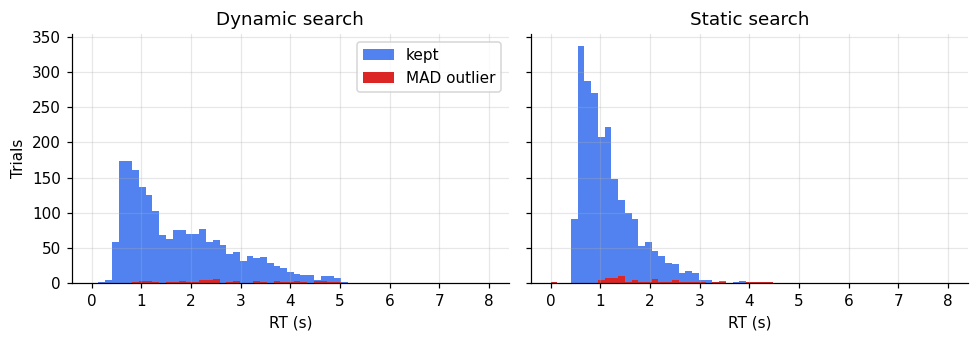

In [2]:
def mad_outlier(x, k=3):
    med = np.median(x)
    mad = 1.4826 * np.median(np.abs(x - med))
    return np.abs(x - med) > k * mad

df = raw.query("resp != -1 and correct == 1").copy()
df["outlier"] = (df.groupby(["sub", "dyn", "target", "setsize"])["rt"]
                   .transform(lambda x: mad_outlier(x.to_numpy())))
print(f"timeouts and errors removed: {1 - len(df) / len(raw):.1%}; "
      f"MAD outliers among correct trials: {df['outlier'].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (dyn, g) in zip(axes, df.groupby("dyn")):
    bins = np.linspace(0, 8, 60)
    ax.hist(g.loc[~g.outlier, "rt"], bins=bins, color="#2563eb", alpha=0.8, label="kept")
    ax.hist(g.loc[g.outlier, "rt"], bins=bins, color="#dc2626", label="MAD outlier")
    ax.set(title=f"{dyn} search", xlabel="RT (s)")
axes[0].set_ylabel("Trials")
axes[0].legend()
plt.tight_layout()
plt.show()

df = df.query("not outlier")

The distributions are clearly skewed, and dynamic search is both slower and more variable.

## Paired t-test, by formula

Start with the simplest question: is target-present search slower in the dynamic condition? We
aggregate to one mean RT per participant and condition, then take the difference $d_i$ for each
participant. Under the null hypothesis the differences have mean zero, and

$$t = \frac{\bar d}{s_d / \sqrt{n}}$$

follows a t-distribution with $n-1$ degrees of freedom.

In [3]:
present = (df.query("target == 'Present'")
             .groupby(["sub", "dyn"])["rt"].mean().unstack())
d = present["Dynamic"] - present["Static"]
n = len(d)
t = d.mean() / (d.std(ddof=1) / np.sqrt(n))
p = 2 * stats.t.sf(abs(t), df=n - 1)
print(f"by hand: mean difference = {d.mean():.3f} s, t({n - 1}) = {t:.2f}, p = {p:.2g}")
print(stats.ttest_rel(present["Dynamic"], present["Static"]))

by hand: mean difference = 0.400 s, t(10) = 3.63, p = 0.0046
TtestResult(statistic=np.float64(3.628607313954578), pvalue=np.float64(0.0046232268929345755), df=np.int64(10))


## The same test by simulation

Where does the t-distribution come from? Simulate it: draw $n$ differences from a population
whose true mean is zero, compute $t$, repeat many times. The histogram of simulated $t$ values
matches the analytic density, which is all the formula promises.

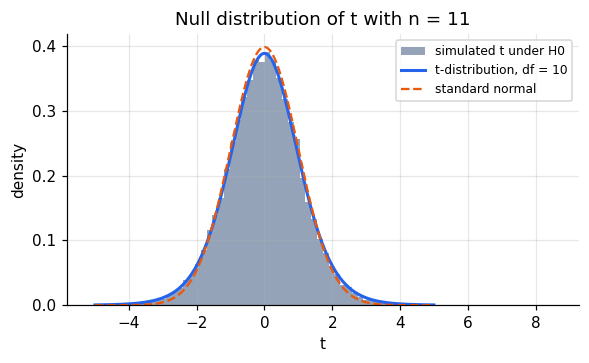

simulated P(|t| > 2.228) = 0.048  (analytic: 0.050)


In [4]:
sims = rng.normal(0, 1, size=(20_000, n))
t_null = sims.mean(1) / (sims.std(1, ddof=1) / np.sqrt(n))

xs = np.linspace(-5, 5, 400)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(t_null, bins=80, density=True, color="#94a3b8", label="simulated t under H0")
ax.plot(xs, stats.t.pdf(xs, n - 1), color="#2563eb", lw=2, label=f"t-distribution, df = {n - 1}")
ax.plot(xs, stats.norm.pdf(xs), color="#ea580c", ls="--", label="standard normal")
ax.set(xlabel="t", ylabel="density", title=f"Null distribution of t with n = {n}")
ax.legend(fontsize=8)
plt.show()
print(f"simulated P(|t| > 2.228) = {(np.abs(t_null) > 2.228).mean():.3f}  (analytic: 0.050)")

The t-distribution has heavier tails than the normal because $s_d$ is itself estimated from only
$n$ = 11 participants. Using a z-test here would make results look more significant than they
are.

## Permutation test: no distributional assumption

The t-test assumes the differences are roughly normal. A permutation test assumes only that,
under the null, the condition labels are exchangeable within a participant. Swapping a
participant's two labels flips the sign of their difference, so the null distribution is
obtained by randomly flipping signs.

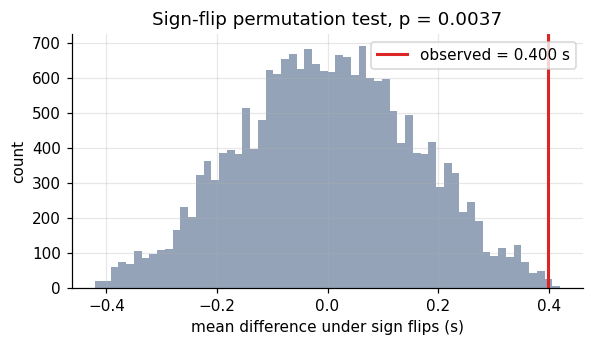

sign-flip p = 0.0037; paired t-test p = 0.0046


In [5]:
def sign_flip_test(d, n_perm=20_000, rng=rng):
    d = np.asarray(d)
    flips = rng.choice([-1, 1], size=(n_perm, len(d)))
    null = (flips * d).mean(1)
    p = (np.sum(np.abs(null) >= abs(d.mean())) + 1) / (n_perm + 1)
    return p, null

p_perm, null = sign_flip_test(d)
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(null, bins=60, color="#94a3b8")
ax.axvline(d.mean(), color="#dc2626", lw=2, label=f"observed = {d.mean():.3f} s")
ax.set(xlabel="mean difference under sign flips (s)", ylabel="count",
       title=f"Sign-flip permutation test, p = {p_perm:.2g}")
ax.legend()
plt.show()
print(f"sign-flip p = {p_perm:.4f}; paired t-test p = {p:.4f}")

With 11 participants there are only $2^{11} = 2048$ distinct sign patterns, so the smallest
attainable two-sided p-value is about 0.001. Ten of the eleven participants are slower in
dynamic search, and the permutation p-value agrees closely with the t-test.

## Effect size

A p-value says whether an effect is distinguishable from zero, not how large it is. For paired
data a common standardised effect size is $d_z = \bar d / s_d$. The raw difference in seconds is
often more informative still.

In [6]:
print(f"d_z = {d.mean() / d.std(ddof=1):.2f}")
print(pg.ttest(present["Dynamic"], present["Static"], paired=True)[["T", "dof", "p-val", "cohen-d", "BF10"]])

d_z = 1.09
               T  dof     p-val   cohen-d    BF10
T-test  3.628607   10  0.004623  1.301432  11.341


Note that pingouin's `cohen-d` for paired data uses the pooled SD of the two conditions, not
$s_d$, so it differs from $d_z$. Always say which one you report.

## Repeated-measures ANOVA

The full design crosses *dynamics* (2) × *set size* (3) for target-present trials. The key
quantity in visual search is the **search slope**: how much RT increases per additional item.
A repeated-measures ANOVA tests the main effects and their interaction while partitioning out
stable differences between participants.

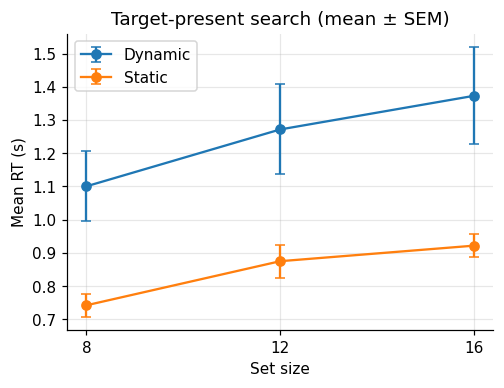

          Source        F  ddof1  ddof2   p-unc     ng2
0            dyn  13.1124      1     10  0.0047  0.3032
1        setsize  24.4292      2     20  0.0000  0.0870
2  dyn * setsize   1.4967      2     20  0.2479  0.0039


pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


In [7]:
cell = (df.query("target == 'Present'")
          .groupby(["sub", "dyn", "setsize"], as_index=False)["rt"].mean())

summary = cell.groupby(["dyn", "setsize"])["rt"].agg(["mean", "sem"]).reset_index()
fig, ax = plt.subplots(figsize=(5, 3.5))
for dyn, g in summary.groupby("dyn"):
    ax.errorbar(g["setsize"], g["mean"], yerr=g["sem"], marker="o", capsize=3, label=dyn)
ax.set(xlabel="Set size", ylabel="Mean RT (s)", xticks=[8, 12, 16],
       title="Target-present search (mean ± SEM)")
ax.legend()
plt.show()

aov = pg.rm_anova(data=cell, dv="rt", within=["dyn", "setsize"], subject="sub", detailed=True)
print(aov[["Source", "F", "ddof1", "ddof2", "p-unc", "ng2"]].round(4))

Both main effects are reliable: dynamic search is slower, and RT grows with set size. The
interaction, which asks whether set size costs more in dynamic search, is not significant.

An interaction in an ANOVA is a difference of differences, and it is often clearer to compute
the quantity it stands for directly. Here that is the per-participant search slope, from a
straight line fitted to each participant's three means, which turns the interaction into a
paired test.

In [8]:
def slope(g):
    return np.polyfit(g["setsize"], g["rt"], 1)[0] * 1000  # ms per item

slopes = (cell.groupby(["sub", "dyn"]).apply(slope, include_groups=False)
              .unstack())
print(slopes.agg(["mean", "sem"]).round(1))
print(pg.ttest(slopes["Dynamic"], slopes["Static"], paired=True)[["T", "dof", "p-val"]])

dyn   Dynamic  Static
mean     34.1    22.4
sem       8.1     2.9
              T  dof     p-val
T-test  1.57614   10  0.146072


Dynamic slopes are larger on average (about 34 vs 22 ms per item), but they vary much more
across participants, so with 11 people the difference is not reliable. This is the same
conclusion as the interaction term, now in units one can interpret. Whether search "has
memory" for visited locations would need more participants, or a model of the search process,
to settle.

## Correlation

Do participants who search slowly in static displays also search slowly in dynamic ones? A
Pearson correlation across participants answers that, and again a permutation test, shuffling
one variable relative to the other, shows what the p-value means.

r = 0.53, permutation p = 0.095, scipy p = 0.090


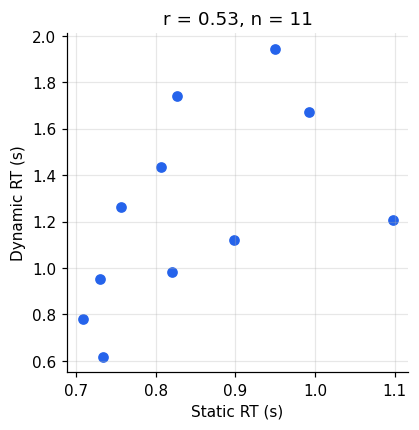

In [9]:
x, y = present["Static"].to_numpy(), present["Dynamic"].to_numpy()
r = np.corrcoef(x, y)[0, 1]
null_r = np.array([np.corrcoef(x, rng.permutation(y))[0, 1] for _ in range(10_000)])
print(f"r = {r:.2f}, permutation p = {(np.abs(null_r) >= abs(r)).mean():.3f}, "
      f"scipy p = {stats.pearsonr(x, y).pvalue:.3f}")

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(x, y, color="#2563eb")
ax.set(xlabel="Static RT (s)", ylabel="Dynamic RT (s)", title=f"r = {r:.2f}, n = {n}")
plt.show()

With 11 participants, a correlation needs to exceed about 0.6 to reach p < .05, so a
correlation of 0.53 is suggestive at best, and its confidence interval is wide. Between-participant correlations need far more participants than
within-participant effects.

## Summary

- Remove outliers with a robust rule (median ± 3 MAD) within participant and condition.
- Aggregate to one value per participant and condition before testing within-participant
  effects.
- A paired t-test is a one-sample test on differences; its null distribution can be simulated.
- A sign-flip permutation test gives the same answer without assuming normality.
- Report effect sizes, and say which effect size you report.
- An ANOVA interaction is a difference of differences; computing the quantity it stands for,
  such as a search slope, makes it interpretable.